In [ ]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, silhouette_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
pd.set_option('display.max_columns', None)

In [11]:
df = pd.read_csv(r"C:\Users\HP ZBOOK\AppData\Local\Temp\366391e7-59f6-4f22-ab19-ddb17f334254_Ay project.zip.254\Customer Data.csv")
df

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.40,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.00,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.00,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.00,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.00,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8945,C19186,28.493517,1.000000,291.12,0.00,291.12,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,325.594462,48.886365,0.500000,6
8946,C19187,19.183215,1.000000,300.00,0.00,300.00,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,275.861322,NaN,0.000000,6
8947,C19188,23.398673,0.833333,144.40,0.00,144.40,0.000000,0.833333,0.000000,0.666667,0.000000,0,5,1000.0,81.270775,82.418369,0.250000,6
8948,C19189,13.457564,0.833333,0.00,0.00,0.00,36.558778,0.000000,0.000000,0.000000,0.166667,2,0,500.0,52.549959,55.755628,0.250000,6


In [12]:
print('Rows and columns:', df.shape)
display(df.head())

Rows and columns: (8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   str    
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHASES_TRX    

In [16]:
display(df.isna().sum()[df.isna().sum() > 0])

CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64

In [17]:
print('Duplicate rows:', df.duplicated().sum())

Duplicate rows: 0


In [18]:
display(df.describe().round(1))

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950.0,8950.0,8950.0,8950.0,8950.0,8950.0,8950.0,8950.0,8950.0,8950.0,8950.0,8950.0,8949.0,8950.0,8637.0,8950.0,8950.0
mean,1564.5,0.9,1003.2,592.4,411.1,978.9,0.5,0.2,0.4,0.1,3.2,14.7,4494.4,1733.1,864.2,0.2,11.5
std,2081.5,0.2,2136.6,1659.9,904.3,2097.2,0.4,0.3,0.4,0.2,6.8,24.9,3638.8,2895.1,2372.4,0.3,1.3
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,50.0,0.0,0.0,0.0,6.0
25%,128.3,0.9,39.6,0.0,0.0,0.0,0.1,0.0,0.0,0.0,0.0,1.0,1600.0,383.3,169.1,0.0,12.0
50%,873.4,1.0,361.3,38.0,89.0,0.0,0.5,0.1,0.2,0.0,0.0,7.0,3000.0,856.9,312.3,0.0,12.0
75%,2054.1,1.0,1110.1,577.4,468.6,1113.8,0.9,0.3,0.8,0.2,4.0,17.0,6500.0,1901.1,825.5,0.1,12.0
max,19043.1,1.0,49039.6,40761.2,22500.0,47137.2,1.0,1.0,1.0,1.5,123.0,358.0,30000.0,50721.5,76406.2,1.0,12.0


In [20]:
df = df.dropna()
display(df.isna().sum())

CUST_ID                             0
BALANCE                             0
BALANCE_FREQUENCY                   0
PURCHASES                           0
ONEOFF_PURCHASES                    0
INSTALLMENTS_PURCHASES              0
CASH_ADVANCE                        0
PURCHASES_FREQUENCY                 0
ONEOFF_PURCHASES_FREQUENCY          0
PURCHASES_INSTALLMENTS_FREQUENCY    0
CASH_ADVANCE_FREQUENCY              0
CASH_ADVANCE_TRX                    0
PURCHASES_TRX                       0
CREDIT_LIMIT                        0
PAYMENTS                            0
MINIMUM_PAYMENTS                    0
PRC_FULL_PAYMENT                    0
TENURE                              0
dtype: int64

In [24]:

df_fe = df.copy()

# 1. Total spending
df_fe["TOTAL_SPENDING"] = (
    df_fe["PURCHASES"] + df_fe["CASH_ADVANCE"]
)

# 2. Average monthly spending
df_fe["AVG_MONTHLY_SPENDING"] = (
    df_fe["TOTAL_SPENDING"] / df_fe["TENURE"].replace(0, np.nan)
)

# 3. Total transactions
df_fe["TOTAL_TRANSACTIONS"] = (
    df_fe["PURCHASES_TRX"] + df_fe["CASH_ADVANCE_TRX"]
)

# 4. Average monthly transactions
df_fe["AVG_MONTHLY_TRANSACTIONS"] = (
    df_fe["TOTAL_TRANSACTIONS"] / df_fe["TENURE"].replace(0, np.nan)
)

# 5. Purchase type
df_fe["PURCHASE_TYPE"] = np.select(
    [
        (df_fe["ONEOFF_PURCHASES"] > 0) &
        (df_fe["INSTALLMENTS_PURCHASES"] > 0),

        df_fe["ONEOFF_PURCHASES"] > 0,

        df_fe["INSTALLMENTS_PURCHASES"] > 0
    ],
    [
        "Both",
        "One-off",
        "Installments"
    ],
    default="No Purchases"
)

# 6. Cash advance user
df_fe["CASH_ADVANCE_USER"] = (
    df_fe["CASH_ADVANCE"] > 0
).astype(int)

# 7. Credit utilization
df_fe["CREDIT_UTILIZATION"] = (
    df_fe["BALANCE"] /
    df_fe["CREDIT_LIMIT"].replace(0, np.nan)
)

# 8. High credit utilization (more than 70%)
df_fe["HIGH_CREDIT_UTILIZATION"] = (
    df_fe["CREDIT_UTILIZATION"] > 0.70
).astype(int)

df_fe.head()

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE,TOTAL_SPENDING,AVG_MONTHLY_SPENDING,TOTAL_TRANSACTIONS,AVG_MONTHLY_TRANSACTIONS,PURCHASE_TYPE,CASH_ADVANCE_USER,CREDIT_UTILIZATION,HIGH_CREDIT_UTILIZATION
0,C10001,40.900749,0.818182,95.40,0.00,95.40,0.000000,0.166667,0.000000,0.083333,0.00,0,2,1000.0,201.802084,139.509787,0.000000,12,95.400000,7.950000,2,0.166667,Installments,0,0.040901,0
1,C10002,3202.467416,0.909091,0.00,0.00,0.00,6442.945483,0.000000,0.000000,0.000000,0.25,4,0,7000.0,4103.032597,1072.340217,0.222222,12,6442.945483,536.912124,4,0.333333,No Purchases,1,0.457495,0
2,C10003,2495.148862,1.000000,773.17,773.17,0.00,0.000000,1.000000,1.000000,0.000000,0.00,0,12,7500.0,622.066742,627.284787,0.000000,12,773.170000,64.430833,12,1.000000,One-off,0,0.332687,0
4,C10005,817.714335,1.000000,16.00,16.00,0.00,0.000000,0.083333,0.083333,0.000000,0.00,0,1,1200.0,678.334763,244.791237,0.000000,12,16.000000,1.333333,1,0.083333,One-off,0,0.681429,0
5,C10006,1809.828751,1.000000,1333.28,0.00,1333.28,0.000000,0.666667,0.000000,0.583333,0.00,0,8,1800.0,1400.057770,2407.246035,0.000000,12,1333.280000,111.106667,8,0.666667,Installments,0,1.005460,1


In [ ]:
features = [
    "BALANCE",
    "PURCHASES_FREQUENCY",
    "CREDIT_LIMIT",
    "PRC_FULL_PAYMENT",
    "AVG_MONTHLY_SPENDING",
    "CREDIT_UTILIZATION"
]

X = df_fe[features]

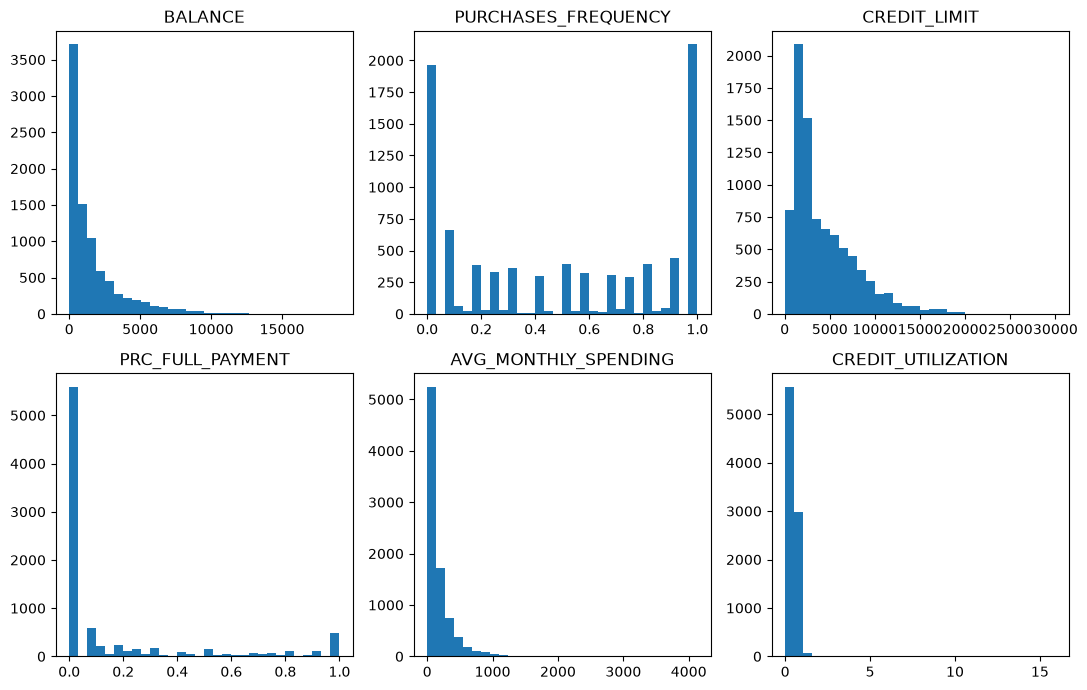

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for ax, col in zip(axes.flat, features):
    ax.hist(df_fe[col].dropna(), bins=30)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [29]:
X_train, X_test = train_test_split(X, test_size=0.20, random_state=42)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (6908, 6) | Test: (1728, 6)


In [32]:
pipeline = Pipeline([
    ('imputer',SimpleImputer(strategy="median")),
    ('scaler',RobustScaler())
])

In [33]:
X_train_pre = pipeline.fit_transform(X_train)
X_test_pre = pipeline.transform(X_test)

In [41]:
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_pre)

In [42]:
X_test_pca = pca.transform(X_test_pre)

In [43]:
print('Before PCA:', X_train_pre.shape[1])
print('After PCA:', X_train_pca.shape[1])
print('Variance retained:', round(pca.explained_variance_ratio_.sum(), 3))

Before PCA: 6
After PCA: 4
Variance retained: 0.956


In [44]:
k_results = []
for k in range(2, 9):
    candidate = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = candidate.fit_predict(X_train_pca)
    k_results.append({
        'K': k,
        'Inertia': candidate.inertia_,
        'Silhouette': silhouette_score(X_train_pca, labels)
    })

In [68]:
k_scores = pd.DataFrame(k_results)
display(k_scores.round(3).T)

,0,1,2,3,4,5,6
K,2.000,3.000,4.000,5.000,6.000,7.000,8.000
Inertia,28352.882,18641.489,15252.545,13102.344,11341.812,9974.740,8778.093
Silhouette,0.553,0.535,0.490,0.416,0.395,0.362,0.330


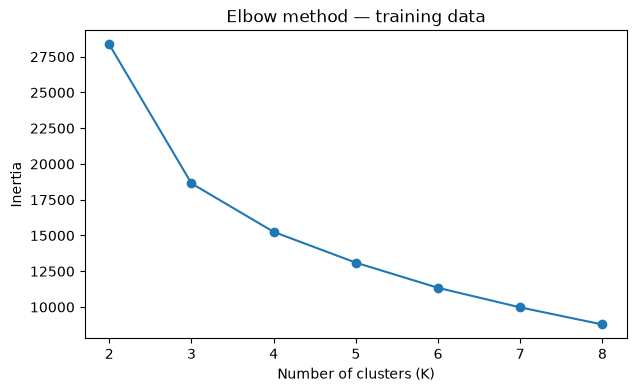

In [46]:
plt.figure(figsize=(7, 4))
plt.plot(k_scores['K'], k_scores['Inertia'], marker='o')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow method — training data')
plt.show()

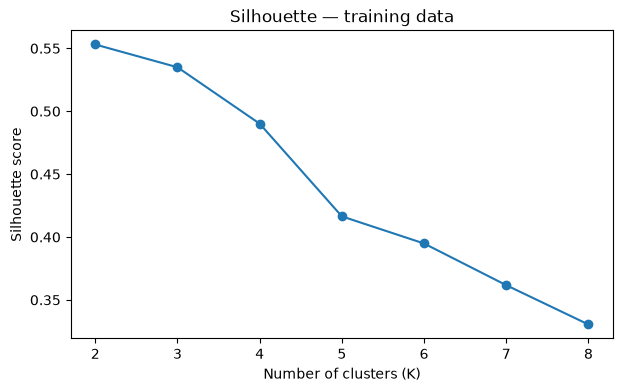

In [47]:
plt.figure(figsize=(7, 4))
plt.plot(k_scores['K'], k_scores['Silhouette'], marker='o')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Silhouette score')
plt.title('Silhouette — training data')
plt.show()

In [49]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
kmeans.fit(X_train_pca)
train_clusters = kmeans.labels_

In [50]:
test_clusters = kmeans.predict(X_test_pca)

In [51]:
print('Training silhouette:', round(silhouette_score(X_train_pca, train_clusters), 3))
print('Test silhouette:', round(silhouette_score(X_test_pca, test_clusters), 3))

Training silhouette: 0.535
Test silhouette: 0.528


In [52]:
display(pd.Series(train_clusters, name="Cluster").value_counts().sort_index())

Cluster
0    4926
1    1106
2     876
Name: count, dtype: int64

In [60]:
cluster_labels = pd.Series(train_clusters, index=X_train.index)

In [61]:
cluster_labels = pd.concat([
    cluster_labels, pd.Series(test_clusters, index=X_test.index)
])

In [62]:
df_fe['Cluster'] = cluster_labels.astype(int)

In [64]:
cluster_profile = df_fe.groupby('Cluster')[
    features
].mean().round(1)
cluster_profile.insert(0, 'Customers', df_fe['Cluster'].value_counts().sort_index())
display(cluster_profile)

,Customers,BALANCE,PURCHASES_FREQUENCY,CREDIT_LIMIT,PRC_FULL_PAYMENT,AVG_MONTHLY_SPENDING,CREDIT_UTILIZATION
Cluster,,,,,,,
0,6144,1211.5,0.4,3547.9,0.0,108.7,0.4
1,1382,160.7,0.8,4853.1,0.8,144.7,0.0
2,1110,5552.2,0.5,9502.4,0.0,605.1,0.6


In [72]:
cluster_names = {
    0: "medium level",
    1: "low level",
    2: "high leve"
}

df_fe["Cluster_Name"] = df_fe["Cluster"].map(cluster_names)

In [73]:
df_fe.head()

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE,TOTAL_SPENDING,AVG_MONTHLY_SPENDING,TOTAL_TRANSACTIONS,AVG_MONTHLY_TRANSACTIONS,PURCHASE_TYPE,CASH_ADVANCE_USER,CREDIT_UTILIZATION,HIGH_CREDIT_UTILIZATION,Cluster,Cluster_Name
0,C10001,40.900749,0.818182,95.40,0.00,95.40,0.000000,0.166667,0.000000,0.083333,0.00,0,2,1000.0,201.802084,139.509787,0.000000,12,95.400000,7.950000,2,0.166667,Installments,0,0.040901,0,0,medium level
1,C10002,3202.467416,0.909091,0.00,0.00,0.00,6442.945483,0.000000,0.000000,0.000000,0.25,4,0,7000.0,4103.032597,1072.340217,0.222222,12,6442.945483,536.912124,4,0.333333,No Purchases,1,0.457495,0,2,high leve
2,C10003,2495.148862,1.000000,773.17,773.17,0.00,0.000000,1.000000,1.000000,0.000000,0.00,0,12,7500.0,622.066742,627.284787,0.000000,12,773.170000,64.430833,12,1.000000,One-off,0,0.332687,0,0,medium level
4,C10005,817.714335,1.000000,16.00,16.00,0.00,0.000000,0.083333,0.083333,0.000000,0.00,0,1,1200.0,678.334763,244.791237,0.000000,12,16.000000,1.333333,1,0.083333,One-off,0,0.681429,0,0,medium level
5,C10006,1809.828751,1.000000,1333.28,0.00,1333.28,0.000000,0.666667,0.000000,0.583333,0.00,0,8,1800.0,1400.057770,2407.246035,0.000000,12,1333.280000,111.106667,8,0.666667,Installments,0,1.005460,1,0,medium level


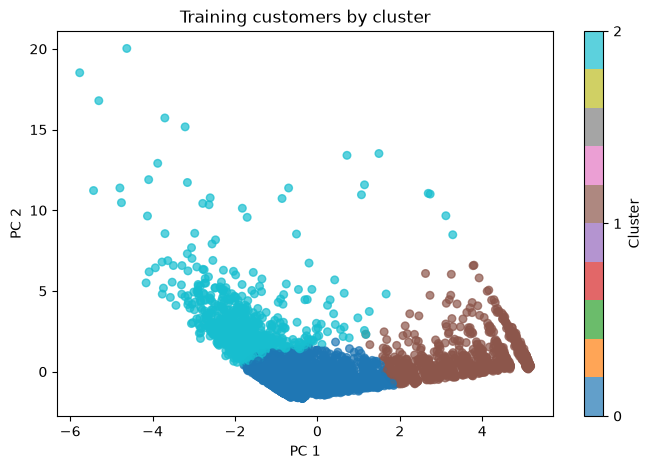

In [75]:
plt.figure(figsize=(8, 5))
points = plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1],
                     c=train_clusters, cmap='tab10', s=30, alpha=0.7)
plt.colorbar(points, label='Cluster', ticks=range(3))
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.title('Training customers by cluster')
plt.show()

In [76]:
classifier = RandomForestClassifier(random_state=42)

In [77]:
classifier_pipeline = Pipeline([
    ('preprocessing', pipeline),
    ('model', classifier)
])

In [78]:
param_grid = {
    'model__n_estimators': [50, 100],
    'model__max_depth': [None, 10]
}

In [79]:
grid_search = GridSearchCV(
    classifier_pipeline, param_grid, cv=3, scoring='accuracy'
)

In [80]:
grid_search.fit(X_train, train_clusters)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [None, 10], 'model__n_estimators': [50, 100]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity o

In [81]:
print('Best CV accuracy:', round(grid_search.best_score_, 3))

Best CV accuracy: 0.992


In [82]:
print(grid_search.best_params_)

{'model__max_depth': 10, 'model__n_estimators': 50}


In [83]:
best_classifier = grid_search.best_estimator_

In [84]:
predicted_clusters = best_classifier.predict(X_test)

In [85]:
print('Test accuracy:', round(accuracy_score(test_clusters, predicted_clusters), 3))

Test accuracy: 0.993


In [ ]:
joblib.dump(best_classifier, 'cluster_classifier.joblib')

['cluster_classifier.joblib']

## Finished

**Workflow:** data → cleaning → features → split → training-only preprocessing/PCA → KMeans labels → train-only GridSearchCV (accuracy) → classifier test accuracy → save and load **only** `cluster_classifier.joblib`.

**For new data:** The saved classifier expects the same `X_train` columns. It handles missing-value imputation, scaling, and encoding internally, but **Age, Tenure_Days, Total_Spending and Total_Purchases must be calculated first**, using consistent rules (including the historical reference date). KMeans is needed only if you want to produce or compare against its original labels, not to run the saved classifier.